# Analisis hasil audit label TRUE

Notebook ini menjawab satu pertanyaan: **berapa presisi label TRUE, dan seberapa konsisten penilainya.**

Isi:

1. Membangun ulang pembagian item yang dipakai saat audit. Benih dan urutannya sama.
2. Presisi per strata beserta selang kepercayaan 95 persen.
3. Grafik: presisi, sebaran jawaban, matriks kesepakatan.
4. Item yang dinilai tidak cocok, tidak jelas, dan yang diperselisihkan, lengkap dengan gambarnya.
5. Ringkasan disimpan ke `hasil_audit.json`.

Masukan: `jawaban_audit.json` di folder ini, dan `data/07_pairs.jsonl` di akar repo.

Grafik memakai matplotlib. Jalankan notebook dengan kernel `.venv` di akar repo.


In [1]:
from pathlib import Path
import base64
import hashlib
import html as html_mod
import io
import json
import random
import re
from collections import Counter

import numpy as np
import pandas as pd
from scipy.stats import beta
from PIL import Image
from IPython.display import HTML, display

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e4e7",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

BASE = Path.cwd()
ROOT = BASE.parents[1]
DATA = ROOT / "data"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)

SEED = 20261119
PER_STRATUM = 60
ORANG = 4
OVERLAP_POS = [0, 6, 12, 18, 24, 30, 36, 42, 48, 54]

assert (DATA / "07_pairs.jsonl").exists(), f"07_pairs.jsonl tidak ditemukan di {DATA}"
print("akar repo:", ROOT)
print("matplotlib:", matplotlib.__version__)


akar repo: /home/prayudahlah/projects/college/ml/image-text-verification
matplotlib: 3.11.2


## Apa itu strata A, B, C

Strata bukan label. Ia hanya membagi pasangan TRUE menurut **sumber fotonya**, karena risikonya berbeda.

| Strata | Ciri | Arti | Jumlah |
|---|---|---|---|
| A | kredit memuat "Kompas" atau "ANTARA FOTO" | foto jurnalistik, dibuat atau dipilih redaksi untuk artikel itu | 3.114 (47%) |
| B | caption dimulai "Ilustrasi", atau kredit stok/AI: Shutterstock, Pexels, Unsplash, Freepik, iStock, Getty, Pixabay, Canva, Magnific, "AI generatif" | foto hiasan, tidak terikat peristiwa tertentu | 694 (10,5%) |
| C | sisanya: kredit instansi (Dok. BPBD, Humas, Polres) atau tanpa kredit | asal-usul tidak pasti; bisa foto peristiwa itu, bisa foto lama yang dipakai ulang | 2.816 (42,5%) |

Alasannya sederhana. Foto A hampir pasti diambil untuk berita itu. Foto B tidak dimaksudkan menggambarkan peristiwa, jadi caption-nya hanya menyebut tema. Foto C di tengah: kadang dokumentasi resmi peristiwa, kadang arsip.

Karena itu sampelnya diambil 60 per strata, bukan 180 acak. Tujuannya supaya presisi tiap strata bisa dilaporkan sendiri, bukan hanya rata-ratanya.


In [2]:
def image_name(url: str) -> str:
    return hashlib.sha1(url.encode()).hexdigest()[:24] + ".jpg"


def stratum(caption: str) -> str:
    c = caption or ""
    if re.match(r"\s*ilustrasi", c, re.I) or re.search(
        r"(shutterstock|pexels|unsplash|freepik|istock|getty|pixabay|canva|magnific"
        r"|ai generatif|dibuat dengan ai|generated by)", c, re.I):
        return "B"
    if re.search(r"(kompas|antara foto|antara/)", c, re.I):
        return "A"
    return "C"


BEKU = BASE / "items_audit.json"
beku = json.loads(BEKU.read_text()) if BEKU.exists() else None

if beku is not None:
    ukuran = beku["populasi"]
    print("populasi dari daftar beku:", ukuran, "| total", sum(ukuran.values()))
else:
    pairs = [json.loads(l) for l in open(DATA / "07_pairs.jsonl")]
    pool = {s: [] for s in "ABC"}
    for p in pairs:
        if p["label"] != "true":
            continue
        if not (DATA / "images" / image_name(p["image"])).exists():
            continue
        pool[stratum(p["caption"])].append(p)
    ukuran = {s: len(pool[s]) for s in "ABC"}
    print("populasi dari 07_pairs.jsonl:", ukuran, "| total", sum(ukuran.values()))


populasi dari daftar beku: {'A': 3114, 'B': 694, 'C': 2816} | total 6624


In [3]:
if beku is not None:
    items = beku["items"]
    print("item dari daftar beku:", len(items),
          "| ganda:", sum(1 for it in items if len(it["raters"]) > 1))
else:
    rng = random.Random(SEED)
    items = []
    for s in "ABC":
        rows = pool[s][:]
        rng.shuffle(rows)
        rows = rows[:PER_STRATUM]
        per_blok = PER_STRATUM // ORANG
        for i, r in enumerate(rows):
            items.append({"stratum": s, "blok": i // per_blok + 1,
                          "caption": r["caption"], "source": r["source"],
                          "image": r["image"]})
    items.sort(key=lambda r: (r["stratum"], r["blok"]))
    for n, it in enumerate(items, 1):
        it["id"] = f"T{n:03d}"
        it["raters"] = [it["blok"]]
    for s in "ABC":
        grup = [it for it in items if it["stratum"] == s]
        for k, idx in enumerate(OVERLAP_POS):
            it = grup[idx]
            lain = [o for o in range(1, ORANG + 1) if o != it["blok"]]
            it["raters"].append(lain[k % len(lain)])
    for it in items:
        it["raters"] = sorted(set(it["raters"]))
    print("item dibangun dari benih:", len(items))


item dari daftar beku: 180 | ganda: 30


In [4]:
answers = json.loads((BASE / "jawaban_audit.json").read_text())
nama = {a["grup"]: a["nama"] for a in answers}
jawab = {a["grup"]: {r["id"]: r["jawaban"] for r in a["jawaban"]} for a in answers}

ids = {it["id"] for it in items}
for g, v in jawab.items():
    asing = set(v) - ids
    print(f'{nama[g]:8s} menjawab {len(v):3d} | id di luar daftar: {len(asing)}')


Yuda     menjawab  54 | id di luar daftar: 0
Rexy     menjawab  51 | id di luar daftar: 0
Darell   menjawab  54 | id di luar daftar: 0
Talitha  menjawab  51 | id di luar daftar: 0


In [5]:
def cp(k, n, alpha=0.05):
    lo = 0.0 if k == 0 else beta.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - alpha / 2, k + 1, n - k)
    return lo, hi


baris = []
for s in "ABC":
    c = Counter()
    for it in items:
        if it["stratum"] != s:
            continue
        v = jawab[it["blok"]].get(it["id"])
        if v:
            c[v] += 1
    n = c["cocok"] + c["tidak"]
    p = c["cocok"] / n
    lo, hi = cp(c["cocok"], n)
    baris.append({"strata": s, "cocok": c["cocok"], "tidak": c["tidak"], "ragu": c["ragu"],
                  "n dinilai": n, "presisi": round(p, 3),
                  "CI bawah": round(lo, 3), "CI atas": round(hi, 3)})

per_strata = pd.DataFrame(baris)

bobot = {s: ukuran[s] / sum(ukuran.values()) for s in "ABC"}
tertimbang = sum(bobot[r["strata"]] * r["presisi"] for _, r in per_strata.iterrows())
k = int(per_strata["cocok"].sum())
n = int(per_strata["n dinilai"].sum())
lo, hi = cp(k, n)

ringkas = pd.DataFrame([
    {"cara": "gabungan sederhana", "nilai": f"{k}/{n} = {k/n:.3f} (CI {lo:.3f}-{hi:.3f})"},
    {"cara": "gabungan berbobot populasi", "nilai": f"{tertimbang:.3f}"},
    {"cara": "ragu dihitung salah", "nilai": f"{k}/{len(items)} = {k/len(items):.3f}"},
])

display(per_strata)
display(ringkas)


,strata,cocok,tidak,ragu,n dinilai,presisi,CI bawah,CI atas
0,A,56,3,1,59,0.949,0.859,0.989
1,B,54,3,3,57,0.947,0.854,0.989
2,C,52,5,3,57,0.912,0.807,0.971


,cara,nilai
0,gabungan sederhana,162/173 = 0.936 (CI 0.889-0.968)
1,gabungan berbobot populasi,0.933
2,ragu dihitung salah,162/180 = 0.900


## Grafik

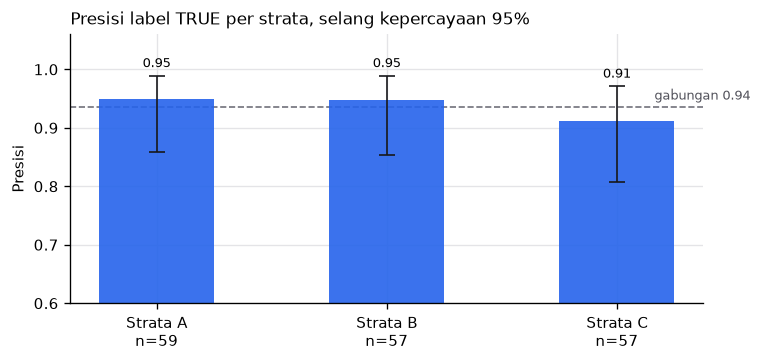

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 3.1))
x = np.arange(len(per_strata))
ax.bar(x, per_strata["presisi"], width=0.5, color="#2563eb", alpha=0.9, zorder=2)
ax.errorbar(x, per_strata["presisi"],
            yerr=[per_strata["presisi"] - per_strata["CI bawah"],
                  per_strata["CI atas"] - per_strata["presisi"]],
            fmt="none", ecolor="#18181b", capsize=5, lw=1, zorder=3)
ax.axhline(k / n, ls="--", lw=1, color="#71717a", zorder=1)
ax.text(len(x) - 0.42, k / n + 0.012, f"gabungan {k/n:.2f}", ha="right",
        fontsize=8, color="#52525b")
for i, (v, atas) in enumerate(zip(per_strata["presisi"], per_strata["CI atas"])):
    ax.text(i, atas + 0.015, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f"Strata {s}\nn={nn}" for s, nn in zip(per_strata["strata"], per_strata["n dinilai"])])
ax.set_ylim(0.6, 1.06)
ax.set_ylabel("Presisi")
ax.set_title("Presisi label TRUE per strata, selang kepercayaan 95%", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "presisi_strata.png", dpi=200, bbox_inches="tight")
plt.show()


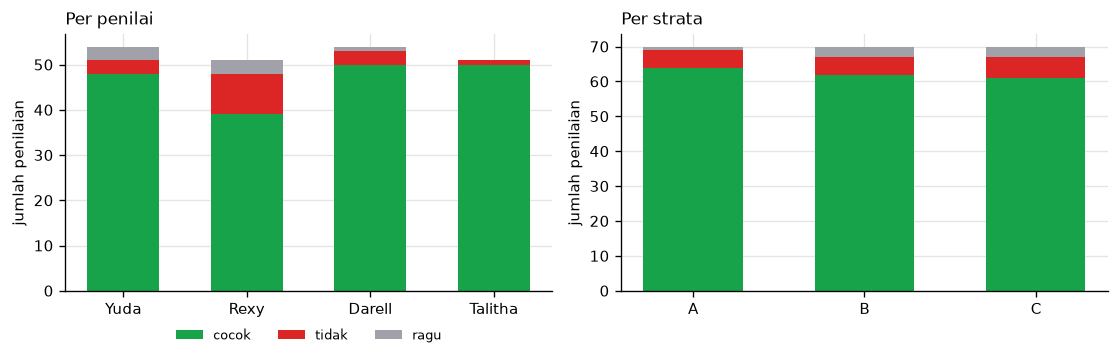

In [7]:
urut = ["cocok", "tidak", "ragu"]
warna = {"cocok": "#16a34a", "tidak": "#dc2626", "ragu": "#a1a1aa"}

panjang = []
for it in items:
    for g in it["raters"]:
        v = jawab[g].get(it["id"])
        if v:
            panjang.append({"penilai": nama[g], "strata": it["stratum"], "jawaban": v})
panjang = pd.DataFrame(panjang)


def tabel(kolom):
    return (panjang.pivot_table(index=kolom, columns="jawaban", values="penilai",
                                aggfunc="count", fill_value=0)
                   .reindex(columns=urut, fill_value=0))


per_orang = tabel("penilai")
urutan_nama = [nama[g] for g in sorted(nama)]
per_orang = per_orang.reindex([x for x in urutan_nama if x in per_orang.index]).fillna(0)
per_strata_j = tabel("strata").reindex(["A", "B", "C"]).fillna(0)

fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.1))
for ax, tab, judul in ((axs[0], per_orang, "Per penilai"),
                       (axs[1], per_strata_j, "Per strata")):
    bawah = np.zeros(len(tab))
    for kol in urut:
        v = tab[kol].to_numpy()
        ax.bar(tab.index, v, bottom=bawah, color=warna[kol], label=kol, width=0.58, zorder=2)
        bawah += v
    ax.set_title(judul, loc="left", fontsize=10)
    ax.set_ylabel("jumlah penilaian")
axs[0].legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.10))
fig.tight_layout()
fig.savefig(FIG / "sebaran_jawaban.png", dpi=200, bbox_inches="tight")
plt.show()


In [8]:
def kappa(pasangan):
    n = len(pasangan)
    po = sum(1 for a, b in pasangan if a == b) / n
    ca = Counter(a for a, _ in pasangan)
    cb = Counter(b for _, b in pasangan)
    pe = sum((ca[c] / n) * (cb[c] / n) for c in set(ca) | set(cb))
    return (po - pe) / (1 - pe), po, pe


def ac1(pasangan, q):
    n = len(pasangan)
    po = sum(1 for a, b in pasangan if a == b) / n
    pi = {}
    for c in set(a for a, _ in pasangan) | set(b for _, b in pasangan):
        pi[c] = (sum(1 for a, _ in pasangan if a == c) +
                 sum(1 for _, b in pasangan if b == c)) / (2 * n)
    pe = sum(v * (1 - v) for v in pi.values()) / (q - 1)
    return (po - pe) / (1 - pe), po, pe


dbl = []
for it in items:
    if len(it["raters"]) < 2:
        continue
    r1, r2 = it["raters"][:2]
    a, b = jawab[r1].get(it["id"]), jawab[r2].get(it["id"])
    if a and b:
        dbl.append({"id": it["id"], "strata": it["stratum"], "caption": it["caption"],
                    "penilai 1": nama[r1], "jawaban 1": a,
                    "penilai 2": nama[r2], "jawaban 2": b})

ganda_df = pd.DataFrame(dbl).sort_values(["strata", "id"])
pasangan = list(zip(ganda_df["jawaban 1"], ganda_df["jawaban 2"]))
k3, po3, pe3 = kappa(pasangan)
a3, _, _ = ac1(pasangan, 3)
biner = [(a, b) for a, b in pasangan if "ragu" not in (a, b)]
k2, po2, pe2 = kappa(biner)

reliabilitas = pd.DataFrame([
    {"ukuran": "item ganda terpakai", "nilai": len(pasangan)},
    {"ukuran": "sepakat", "nilai": sum(1 for a, b in pasangan if a == b)},
    {"ukuran": "kesepakatan mentah", "nilai": round(po3, 3)},
    {"ukuran": "kesepakatan kebetulan", "nilai": round(pe3, 3)},
    {"ukuran": "Cohen kappa, 3 kelas", "nilai": round(k3, 3)},
    {"ukuran": "Gwet AC1, 3 kelas", "nilai": round(a3, 3)},
])
display(reliabilitas)
display(ganda_df[ganda_df["jawaban 1"] != ganda_df["jawaban 2"]]
        [["id", "strata", "penilai 1", "jawaban 1", "penilai 2", "jawaban 2"]])


,ukuran,nilai
0,item ganda terpakai,30.000
1,sepakat,24.000
2,kesepakatan mentah,0.800
3,kesepakatan kebetulan,0.818
4,"Cohen kappa, 3 kelas",-0.098
5,"Gwet AC1, 3 kelas",0.780


,id,strata,penilai 1,jawaban 1,penilai 2,jawaban 2
2,T013,A,Yuda,cocok,Talitha,tidak
7,T043,A,Rexy,tidak,Darell,cocok
14,T085,B,Rexy,cocok,Darell,tidak
17,T103,B,Rexy,tidak,Darell,cocok
24,T145,C,Rexy,tidak,Darell,cocok
27,T163,C,Rexy,tidak,Darell,cocok


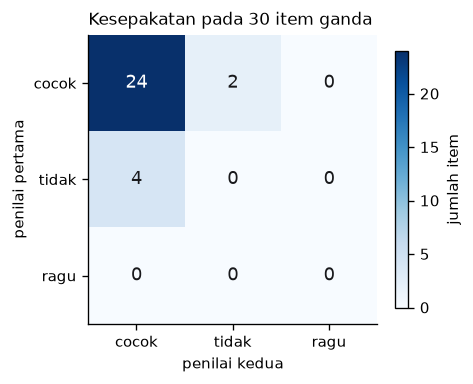

In [9]:
kategori = ["cocok", "tidak", "ragu"]
mat = pd.crosstab(ganda_df["jawaban 1"], ganda_df["jawaban 2"]).reindex(
    index=kategori, columns=kategori, fill_value=0)

fig, ax = plt.subplots(figsize=(4.0, 3.4))
im = ax.imshow(mat.to_numpy(), cmap="Blues")
ax.set_xticks(range(3)); ax.set_xticklabels(kategori)
ax.set_yticks(range(3)); ax.set_yticklabels(kategori)
ax.set_xlabel("penilai kedua"); ax.set_ylabel("penilai pertama")
ax.grid(False)
for i in range(3):
    for j in range(3):
        v = int(mat.to_numpy()[i, j])
        ax.text(j, i, v, ha="center", va="center", fontsize=11,
                color="white" if v > mat.to_numpy().max() / 2 else "#18181b")
ax.set_title("Kesepakatan pada 30 item ganda", loc="left", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8, label="jumlah item")
fig.tight_layout()
fig.savefig(FIG / "matriks_kesepakatan.png", dpi=200, bbox_inches="tight")
plt.show()


## Item yang perlu dilihat

Tiga daftar: dinilai tidak cocok, dinilai tidak jelas, dan yang diperselisihkan.

In [10]:
def thumb(path, w=640, q=78):
    im = Image.open(path).convert("RGB")
    if im.width > w:
        im = im.resize((w, round(im.height * w / im.width)), Image.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "JPEG", quality=q)
    return base64.b64encode(buf.getvalue()).decode()


def kartu(rows):
    bagian = ['<div style="display:grid;grid-template-columns:repeat(auto-fill,minmax(330px,1fr));gap:14px">']
    for r in rows:
        bagian.append('<div style="border:1px solid #d4d4d8;border-radius:10px;padding:10px;background:#fff;color:#111">')
        bagian.append(f'<img src="data:image/jpeg;base64,{thumb(r["path"])}" style="width:100%;border-radius:6px;display:block">')
        bagian.append(f'<div style="font-size:12px;color:#52525b;margin-top:8px">{r["id"]} · strata {r["strata"]}</div>')
        bagian.append(f'<div style="font-size:13px;line-height:1.4;margin-top:4px">{html_mod.escape(r["caption"])}</div>')
        for baris in r["catatan"]:
            bagian.append(f'<div style="font-size:12px;margin-top:6px">{baris}</div>')
        bagian.append('</div>')
    bagian.append('</div>')
    return HTML("".join(bagian))


def kumpulan(pred):
    rows = []
    for it in items:
        c = pred(it)
        if not c:
            continue
        path = DATA / "images" / image_name(it["image"])
        if not path.exists():
            continue
        rows.append({"id": it["id"], "strata": it["stratum"], "caption": it["caption"],
                     "path": path, "catatan": c})
    return rows


nilai_pemilik = {it["id"]: jawab[it["blok"]].get(it["id"]) for it in items}
print("penampil siap")


penampil siap


dinilai tidak cocok: 11



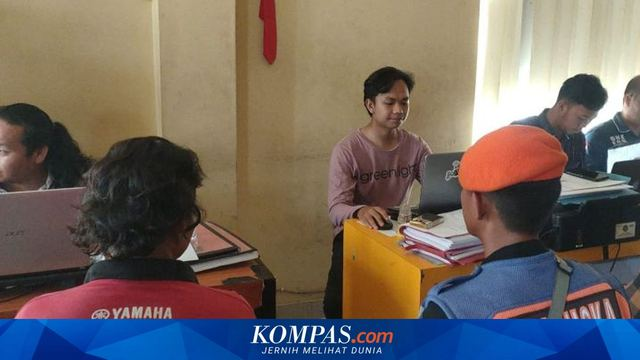
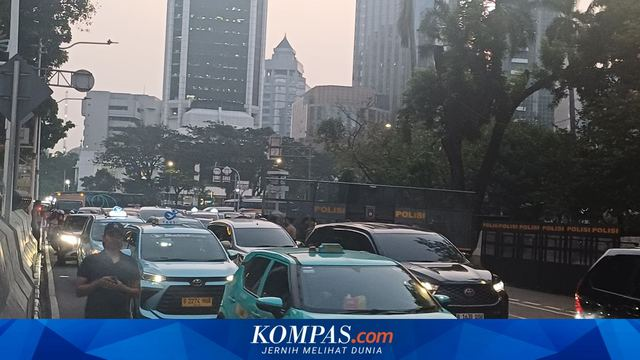
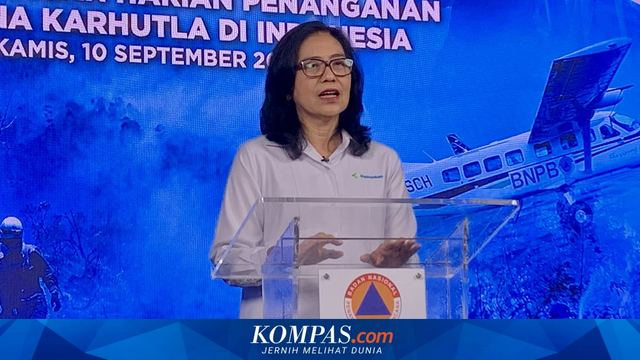
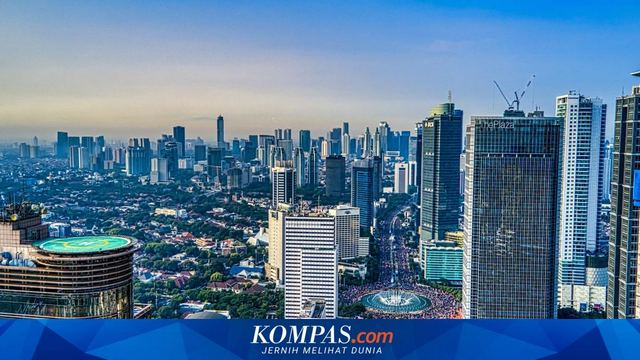
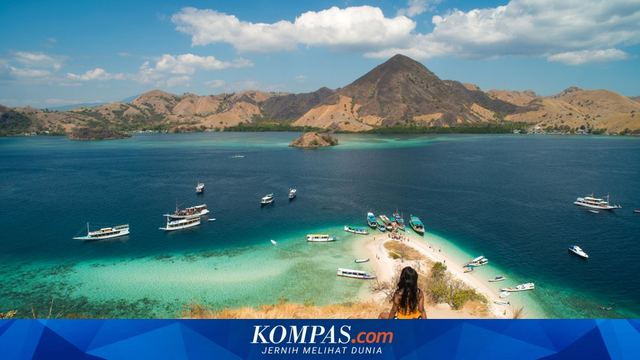
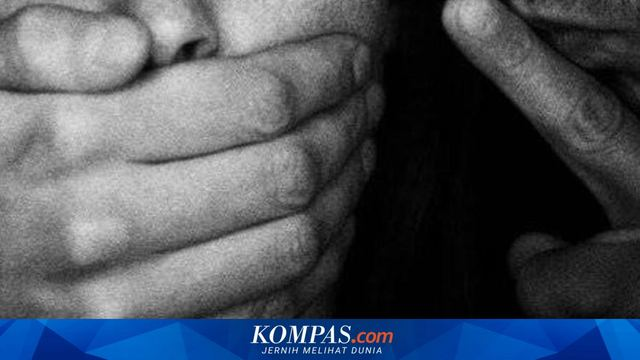
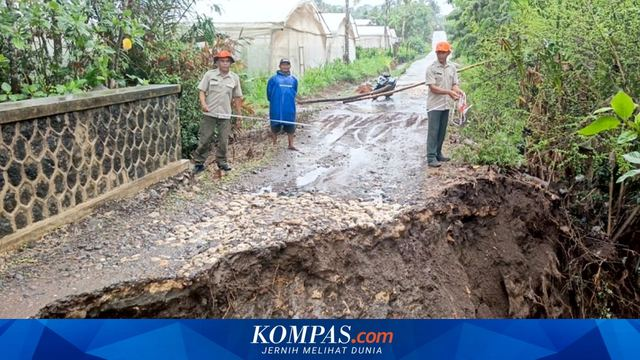
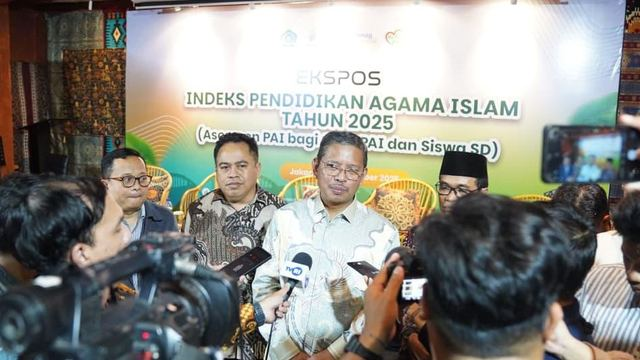
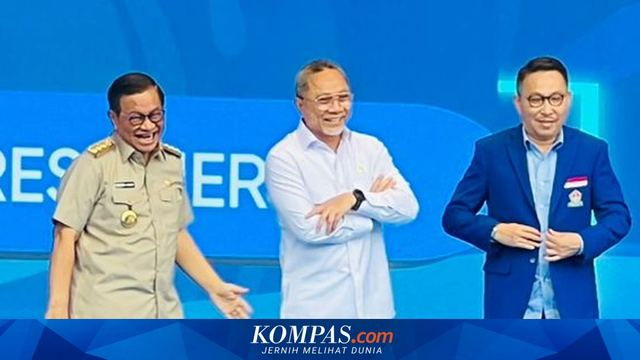
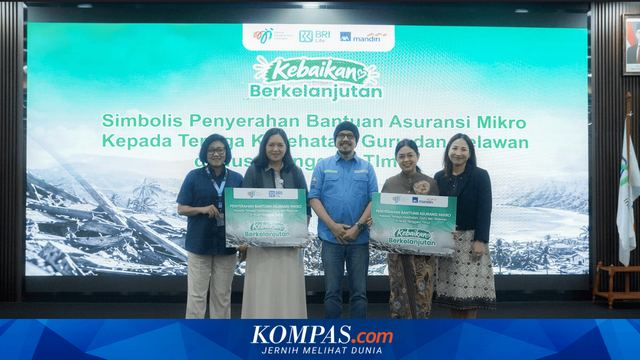
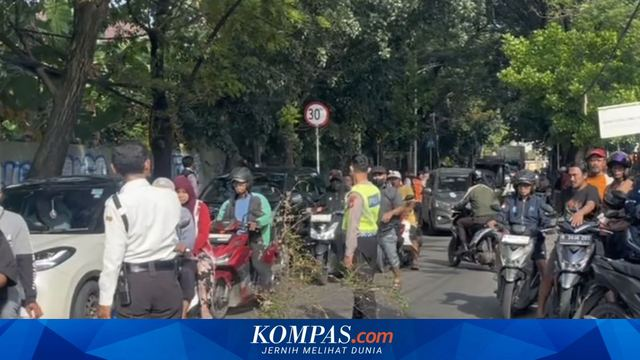

In [11]:
rows = kumpulan(lambda it: [f'{nama[it["blok"]]}: <b>tidak cocok</b>']
                if nilai_pemilik[it["id"]] == "tidak" else None)
print("dinilai tidak cocok:", len(rows))
display(kartu(rows))


dinilai tidak jelas: 7



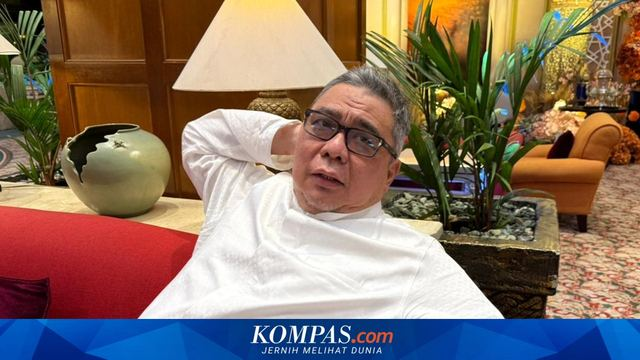
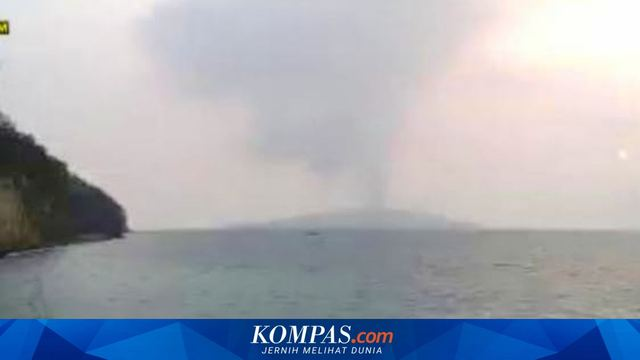
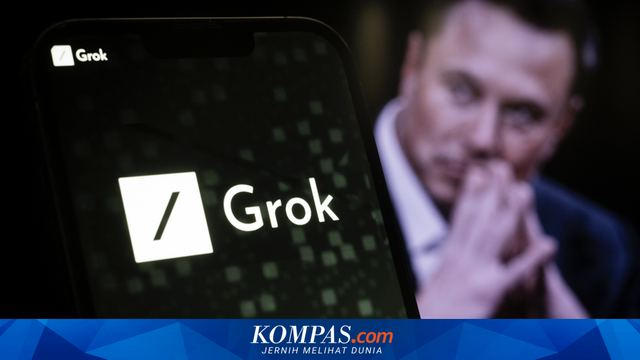
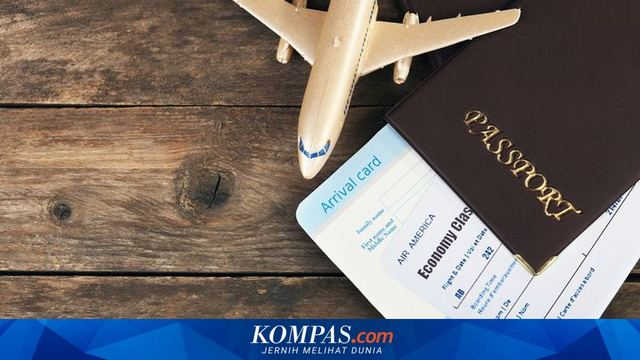
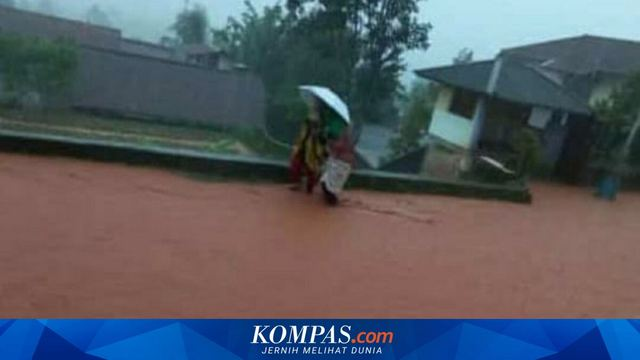
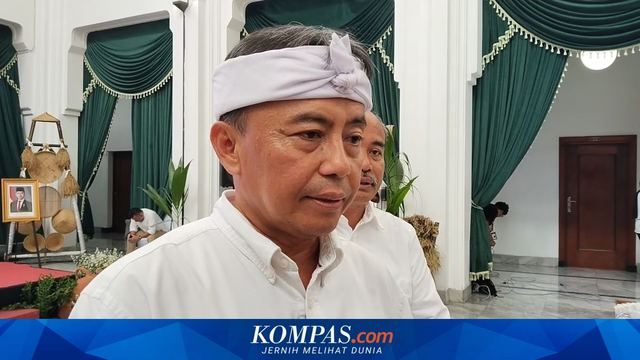
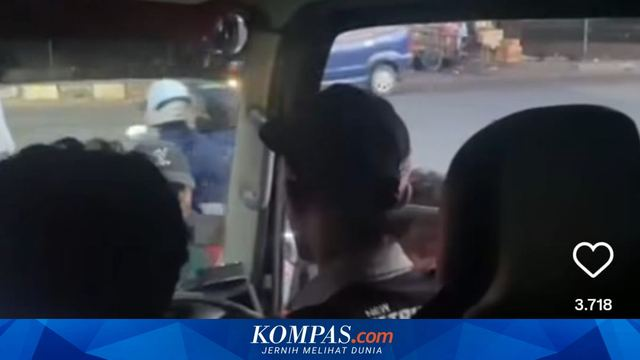

In [12]:
rows = kumpulan(lambda it: [f'{nama[it["blok"]]}: <b>tidak jelas</b>']
                if nilai_pemilik[it["id"]] == "ragu" else None)
print("dinilai tidak jelas:", len(rows))
display(kartu(rows))


diperselisihkan: 6



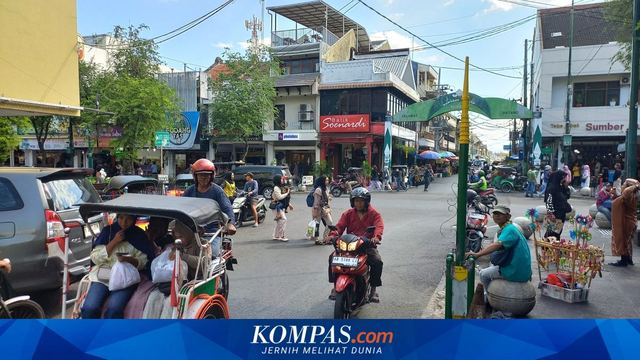
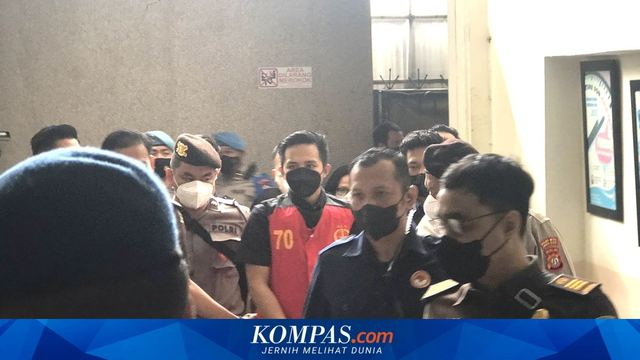
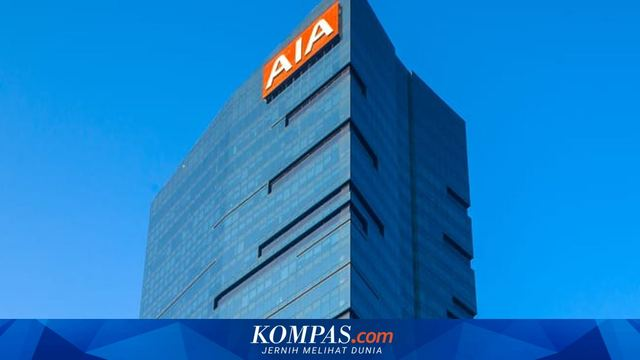
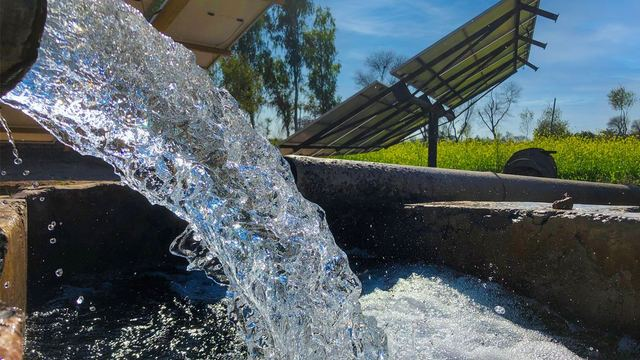
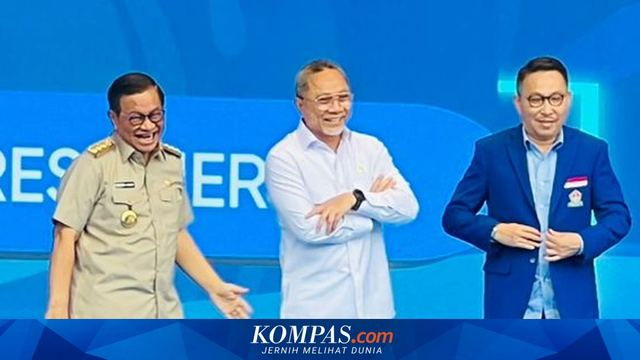
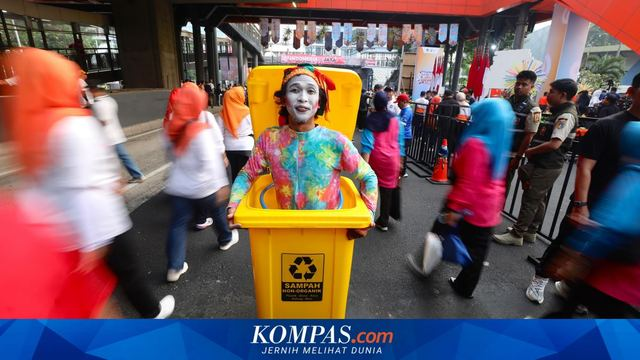

In [13]:
rows = []
for _, r in ganda_df[ganda_df["jawaban 1"] != ganda_df["jawaban 2"]].iterrows():
    it = next(x for x in items if x["id"] == r["id"])
    path = DATA / "images" / image_name(it["image"])
    if not path.exists():
        continue
    rows.append({"id": r["id"], "strata": r["strata"], "caption": r["caption"], "path": path,
                 "catatan": [f'{r["penilai 1"]}: <b>{r["jawaban 1"]}</b>',
                             f'{r["penilai 2"]}: <b>{r["jawaban 2"]}</b>']})
print("diperselisihkan:", len(rows))
display(kartu(rows))


In [14]:
selisih = ganda_df[ganda_df["jawaban 1"] != ganda_df["jawaban 2"]]
hasil = {
    "populasi": ukuran,
    "item": len(items),
    "item_ganda": int(len(ganda_df)),
    "perselisihan_jumlah": int(len(selisih)),
    "per_strata": per_strata.to_dict(orient="records"),
    "presisi_gabungan": round(k / n, 4),
    "ci_gabungan": [round(lo, 4), round(hi, 4)],
    "presisi_tertimbang": round(tertimbang, 4),
    "kesepakatan": {
        "mentah": round(po3, 4),
        "kappa_3_kelas": round(k3, 4),
        "kappa_biner": round(k2, 4),
        "ac1_3_kelas": round(a3, 4),
    },
    "tidak_cocok": [it["id"] for it in items if nilai_pemilik[it["id"]] == "tidak"],
    "tidak_jelas": [it["id"] for it in items if nilai_pemilik[it["id"]] == "ragu"],
    "perselisihan": selisih[["id", "strata", "penilai 1", "jawaban 1",
                             "penilai 2", "jawaban 2"]].to_dict(orient="records"),
}
(BASE / "hasil_audit.json").write_text(json.dumps(hasil, ensure_ascii=False, indent=1))
print("tersimpan:", BASE / "hasil_audit.json")


tersimpan: /home/prayudahlah/projects/college/ml/image-text-verification/experiments/audit/hasil_audit.json


## Cara membaca

**Presisi** adalah porsi pasangan yang dinilai cocok, dari yang dinilai tegas. "Ragu" dikeluarkan dari penyebut dan dilaporkan terpisah.

**Gabungan berbobot** memakai ukuran populasi tiap strata, karena sampelnya 60 per strata dan bukan sebanding. Angka ini yang paling dekat dengan presisi seluruh kelas TRUE.

**Kappa** tidak dipakai sebagai angka utama. Hampir semua jawaban "cocok", sehingga kesepakatan kebetulan mendekati kesepakatan nyata. Yang dilaporkan: kesepakatan mentah, dan AC1 sebagai pembanding yang lebih tahan terhadap sebaran timpang.

**Daftar item** di atas menunjukkan di mana aturan masih kabur. Bukan untuk menentukan siapa yang salah.
